In [17]:
import numpy as np 
import xarray as xr 
import matplotlib.pyplot as plt

In [18]:
isnobal_dir = '/bsushare/hpmarshall-shared/ERW_2026/model_out/erw/wy2026/with_spinup/'
snow_file = 'run20260227/snow.nc'
winddir_file = 'run20260227/wind_direction.nc'


In [19]:
snow = xr.open_dataset(isnobal_dir + test_file)
snow

<xarray.Dataset> Size: 68MB
Dimensions:           (time: 2, y: 1094, x: 865)
Coordinates:
  * time              (time) datetime64[ns] 16B 2026-02-27 2026-02-27T23:00:00
  * y                 (y) float32 4kB 4.329e+06 4.329e+06 ... 4.274e+06
  * x                 (x) float32 3kB 3.11e+05 3.111e+05 ... 3.542e+05 3.542e+05
Data variables:
    thickness         (time, y, x) float32 8MB ...
    snow_density      (time, y, x) float32 8MB ...
    specific_mass     (time, y, x) float32 8MB ...
    liquid_water      (time, y, x) float32 8MB ...
    temp_surf         (time, y, x) float32 8MB ...
    temp_lower        (time, y, x) float32 8MB ...
    temp_snowcover    (time, y, x) float32 8MB ...
    thickness_lower   (time, y, x) float32 8MB ...
    water_saturation  (time, y, x) float32 8MB ...
    projection        |S1 1B ...

In [ ]:
snow = one_day.set_coords('projection')
snow['swe'] = snow['thickness'] * snow['snow_density']
snow

<xarray.Dataset> Size: 68MB
Dimensions:           (time: 2, y: 1094, x: 865)
Coordinates:
  * time              (time) datetime64[ns] 16B 2026-02-27 2026-02-27T23:00:00
  * y                 (y) float32 4kB 4.329e+06 4.329e+06 ... 4.274e+06
  * x                 (x) float32 3kB 3.11e+05 3.111e+05 ... 3.542e+05 3.542e+05
    projection        |S1 1B ...
Data variables:
    thickness         (time, y, x) float32 8MB ...
    snow_density      (time, y, x) float32 8MB ...
    specific_mass     (time, y, x) float32 8MB ...
    liquid_water      (time, y, x) float32 8MB ...
    temp_surf         (time, y, x) float32 8MB ...
    temp_lower        (time, y, x) float32 8MB ...
    temp_snowcover    (time, y, x) float32 8MB ...
    thickness_lower   (time, y, x) float32 8MB ...
    water_saturation  (time, y, x) float32 8MB ...

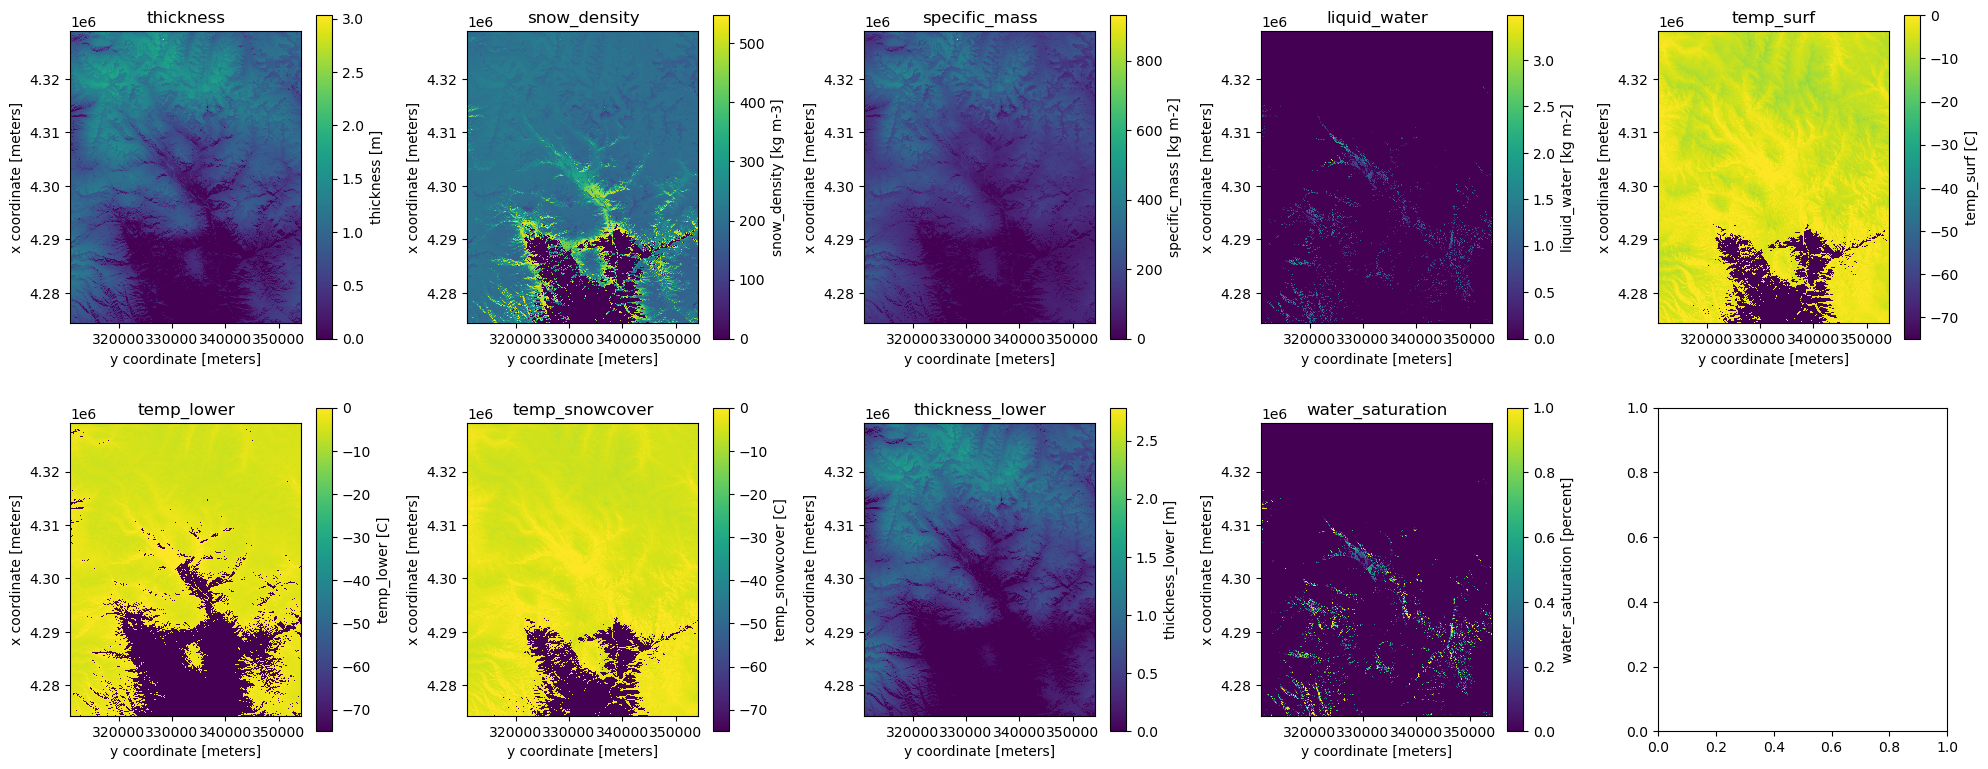

In [ ]:
n = len(snow.data_vars)

fig, axes = plt.subplots(int(np.ceil(n / 5)), 5, figsize=(20, 8))
axes = axes.flatten()

for i, v in enumerate(one_day.data_vars): 
    snow[v].isel(time=0).plot(ax=axes[i])
    axes[i].set_title(v)
    axes[i].set_aspect('equal')

plt.tight_layout()
plt.show()

In [23]:
winddir = xr.open_dataset(isnobal_dir + winddir_file)
winddir

<xarray.Dataset> Size: 91MB
Dimensions:         (time: 24, y: 1094, x: 865)
Coordinates:
  * time            (time) datetime64[ns] 192B 2026-02-27 ... 2026-02-27T23:0...
  * y               (y) float32 4kB 4.329e+06 4.329e+06 ... 4.274e+06 4.274e+06
  * x               (x) float32 3kB 3.11e+05 3.111e+05 ... 3.542e+05 3.542e+05
Data variables:
    wind_direction  (time, y, x) float32 91MB ...
    projection      |S1 1B ...
Attributes:
    Conventions:   CF-1.6
    dateCreated:   2026-08-20 00:14:08
    title:         Distributed Wind direction data from SMRF
    history:       [2026-08-20 00:14:08] Create netCDF4 file
    SMRF_version:  20260310.dev14+gbb8e59064

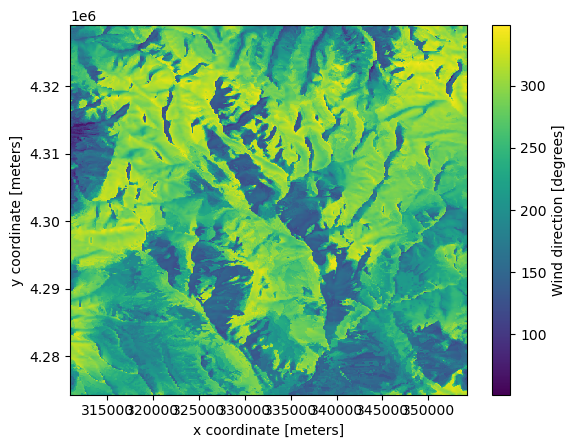

In [25]:
winddir['wind_direction'].mean(dim='time').plot()